In [1]:
import csv
import os
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from nltk.corpus import cmudict, stopwords
from scipy.cluster.hierarchy import dendrogram, leaves_list, linkage
from scipy.spatial.distance import jensenshannon, squareform

# Task 8

Lines per poem / end-words found in CMUdict:
  The Lamb      20 lines,    20 found (100.0%)
  The Tiger     24 lines,    24 found (100.0%)
  Sonnets     2155 lines,  2097 found (97.3%)
  most common end-words not in CMUdict: [('offence', 2), ('niggarding', 1), ('viewest', 1), ('renewest', 1), ('unprovident', 1), ('ruinate', 1), ('departest', 1), ('convertest', 1), ('untrimmed', 1), ('gazeth', 1)]

Stopwords most often used as the line-final word: [('me', 33, '20% of its lines'), ('be', 22, '16% of its lines'), ('you', 12, '12% of its lines'), ('so', 11, '8% of its lines'), ('will', 10, '17% of its lines'), ('now', 9, '20% of its lines'), ('more', 9, '15% of its lines'), ('are', 7, '10% of its lines')]


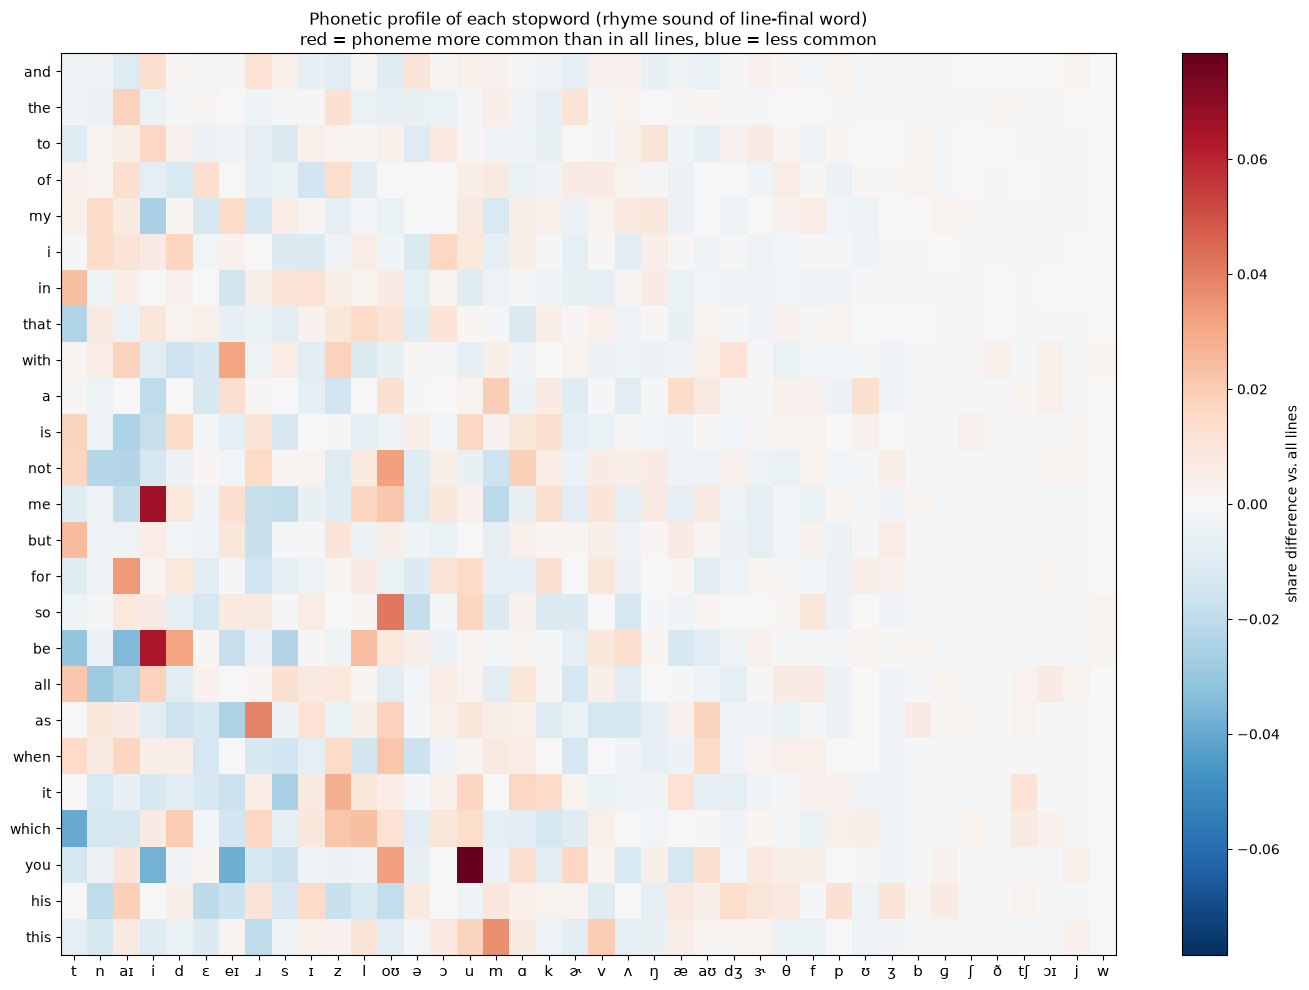

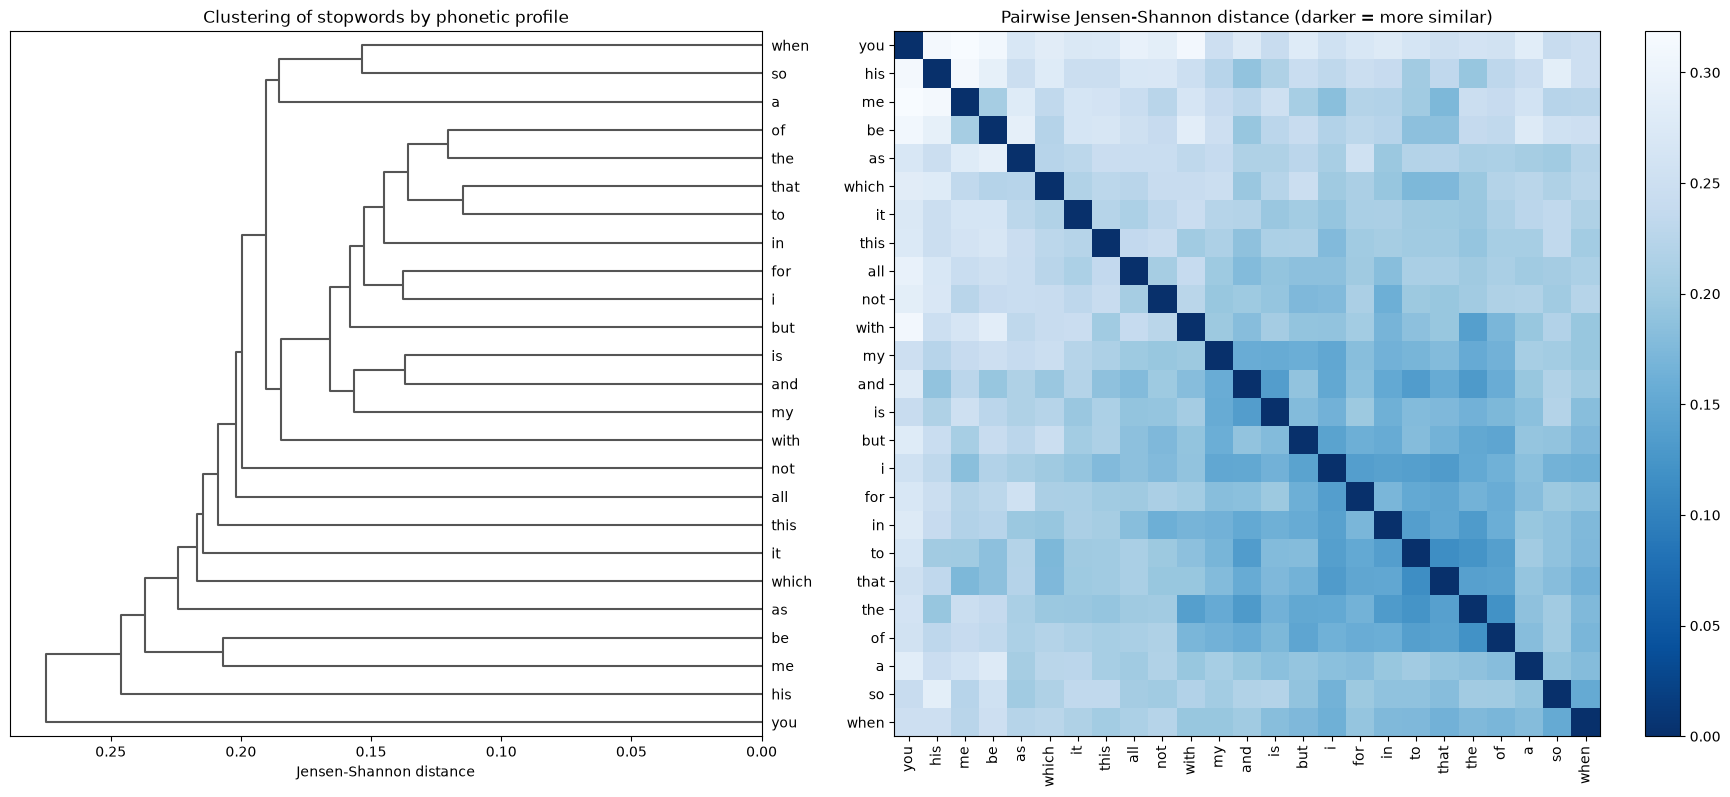

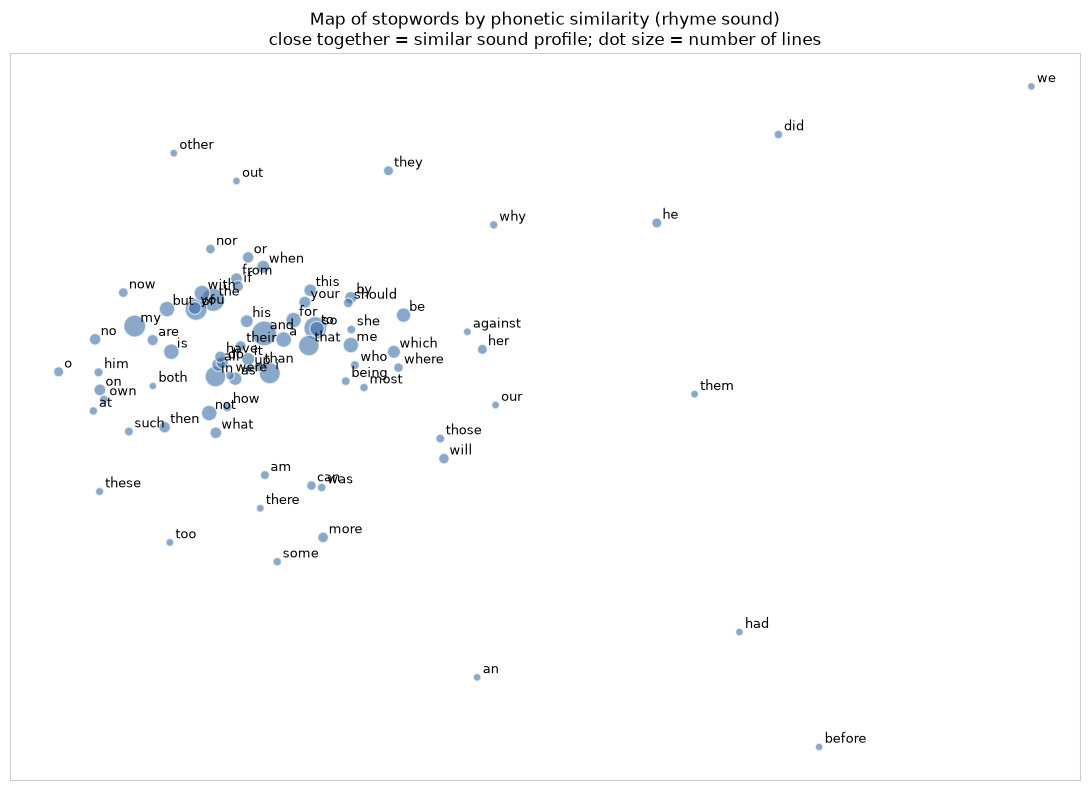

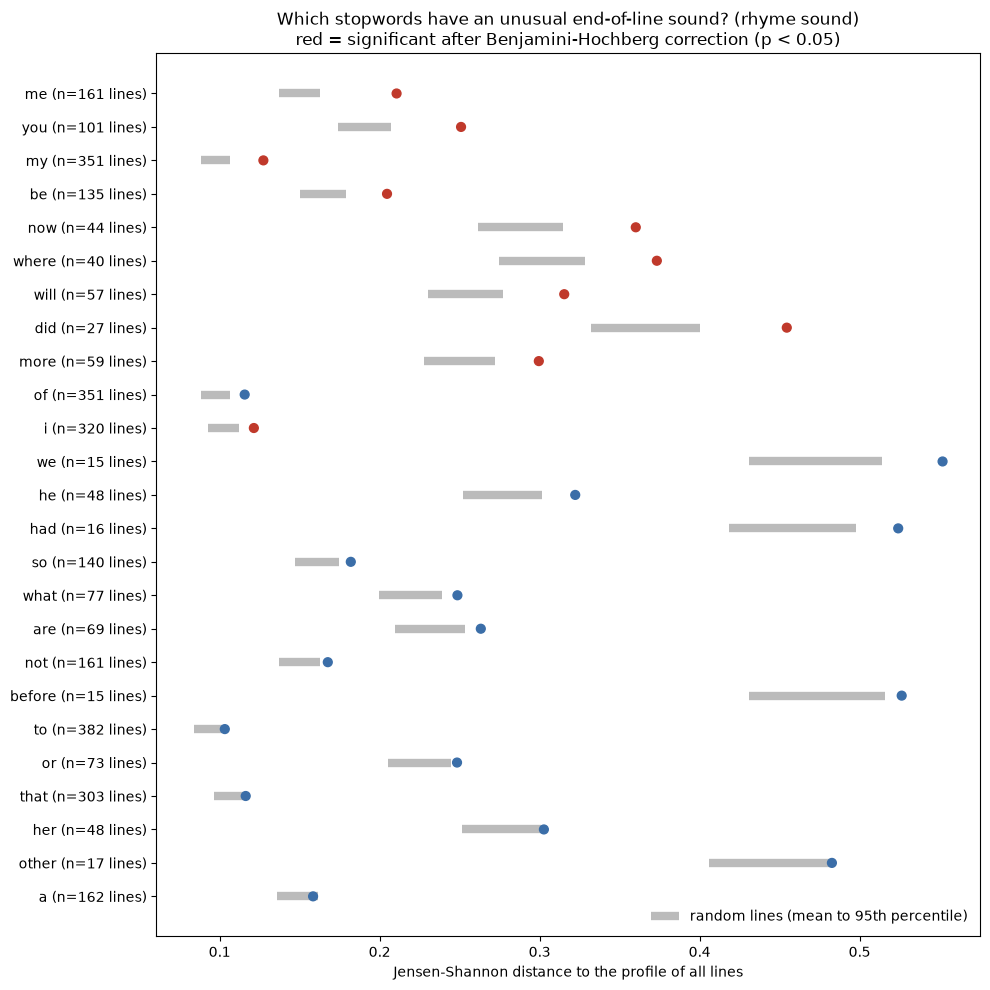


=== rhyme profile: 80 stopwords with >= 15 lines ===
  Jensen-Shannon vs Hellinger agreement (Pearson r): 0.998
  most similar pairs:   [('to', 'that', np.float64(0.115)), ('the', 'of', np.float64(0.12)), ('the', 'to', np.float64(0.123)), ('and', 'the', np.float64(0.131)), ('the', 'in', np.float64(0.132))]
  most different pairs: [('other', 'before', np.float64(0.688)), ('up', 'we', np.float64(0.689)), ('had', 'we', np.float64(0.693)), ('out', 'before', np.float64(0.697)), ('other', 'had', np.float64(0.726))]
  significantly distinctive stopwords: 10 of 80
    me       n= 161 JS=0.211 (random ~0.137) p_adj=0.0200 more: i oʊ l
    you      n= 101 JS=0.251 (random ~0.174) p_adj=0.0200 more: u oʊ ɚ
    my       n= 351 JS=0.127 (random ~0.088) p_adj=0.0267 more: eɪ n ŋ
    will     n=  57 JS=0.315 (random ~0.231) p_adj=0.0333 more: l ɪ ʌ
    now      n=  44 JS=0.360 (random ~0.262) p_adj=0.0333 more: aʊ n ɹ
    did      n=  27 JS=0.454 (random ~0.332) p_adj=0.0333 more: d i p
    be      

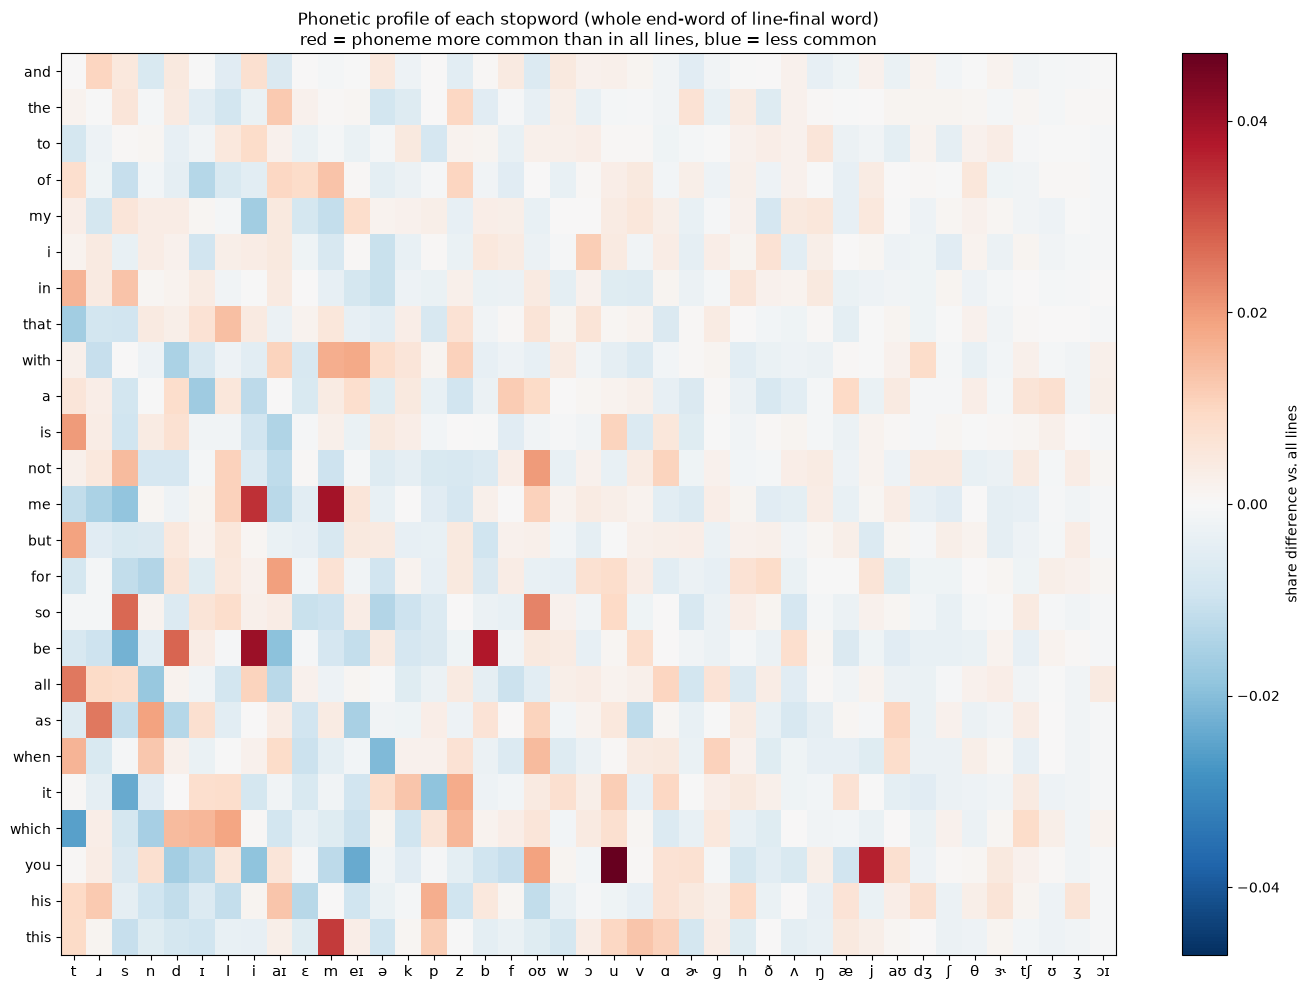

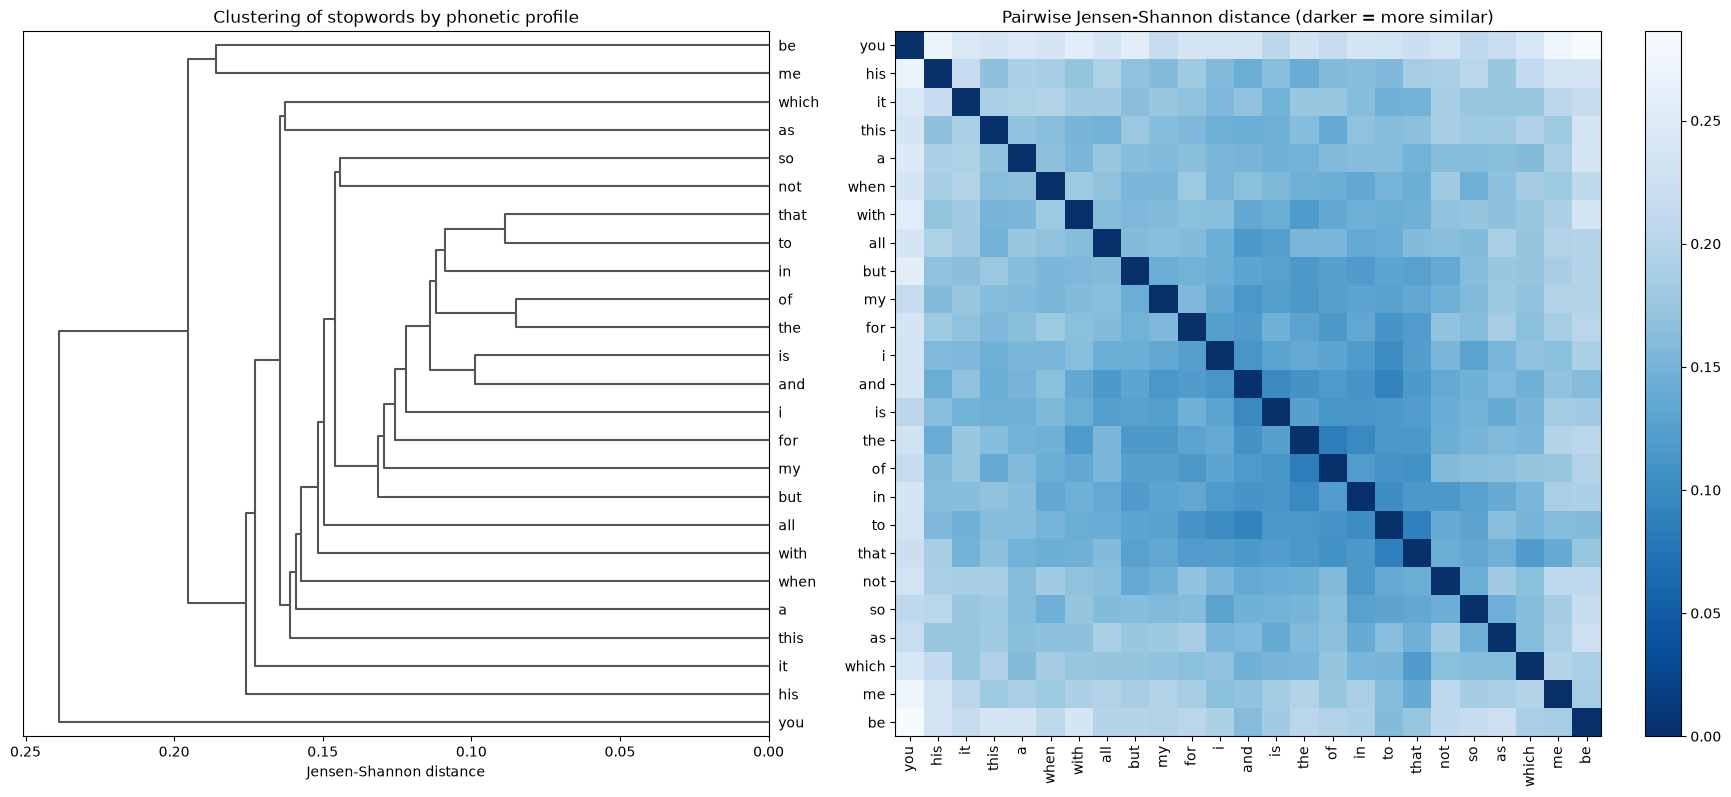

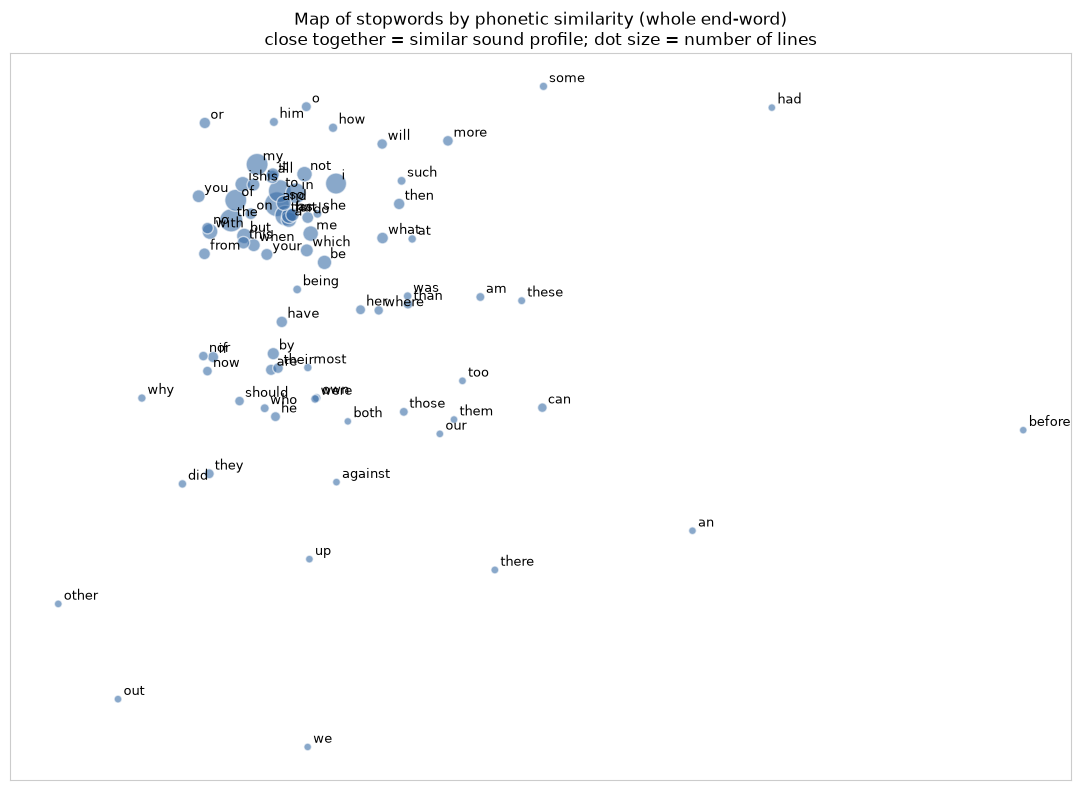

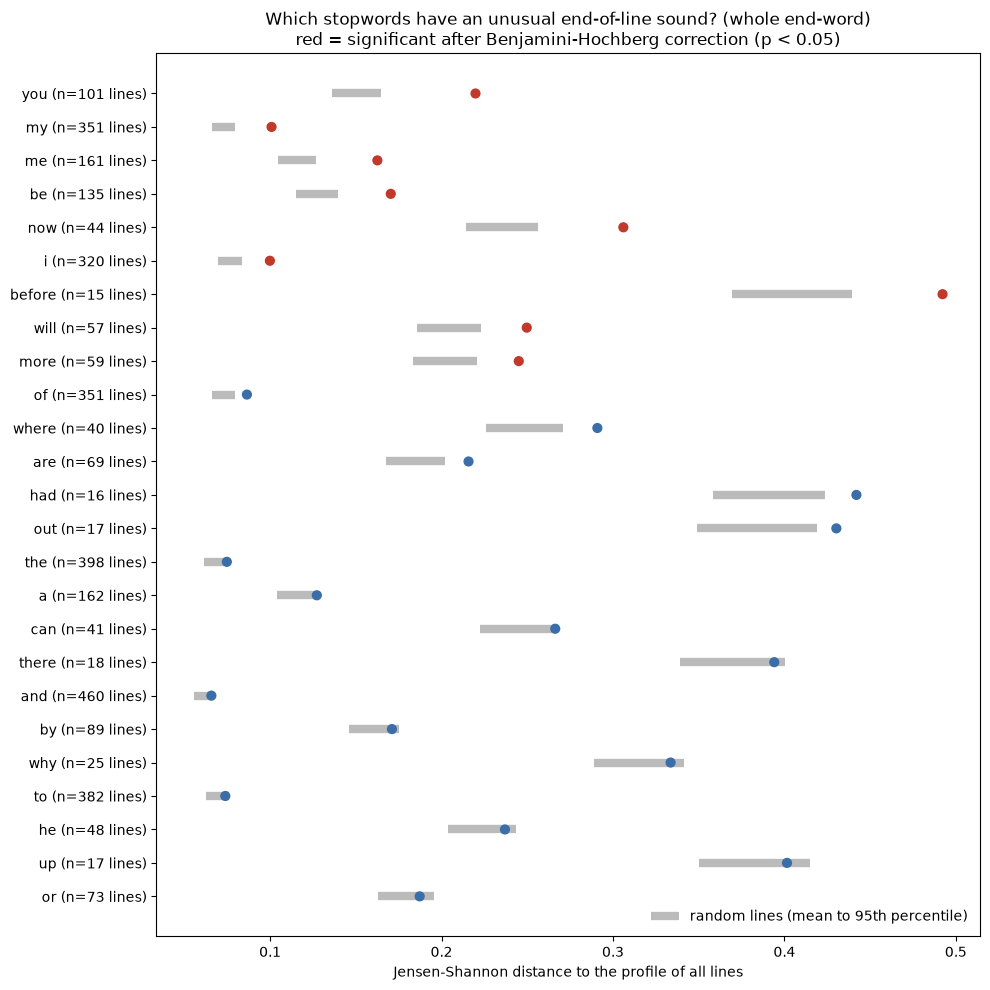


=== word profile: 80 stopwords with >= 15 lines ===
  Jensen-Shannon vs Hellinger agreement (Pearson r): 0.998
  most similar pairs:   [('the', 'of', np.float64(0.085)), ('to', 'that', np.float64(0.089)), ('and', 'to', np.float64(0.093)), ('and', 'is', np.float64(0.099)), ('the', 'in', np.float64(0.099))]
  most different pairs: [('out', 'had', np.float64(0.612)), ('why', 'before', np.float64(0.629)), ('other', 'before', np.float64(0.633)), ('out', 'before', np.float64(0.636)), ('other', 'had', np.float64(0.64))]
  significantly distinctive stopwords: 9 of 80
    my       n= 351 JS=0.101 (random ~0.066) p_adj=0.0100 more: eɪ s ŋ
    me       n= 161 JS=0.163 (random ~0.104) p_adj=0.0100 more: m i oʊ
    be       n= 135 JS=0.170 (random ~0.115) p_adj=0.0100 more: i b d
    you      n= 101 JS=0.220 (random ~0.136) p_adj=0.0100 more: u j oʊ
    i        n= 320 JS=0.100 (random ~0.070) p_adj=0.0160 more: ɔ ð b
    now      n=  44 JS=0.306 (random ~0.214) p_adj=0.0200 more: n aʊ ə
    will 

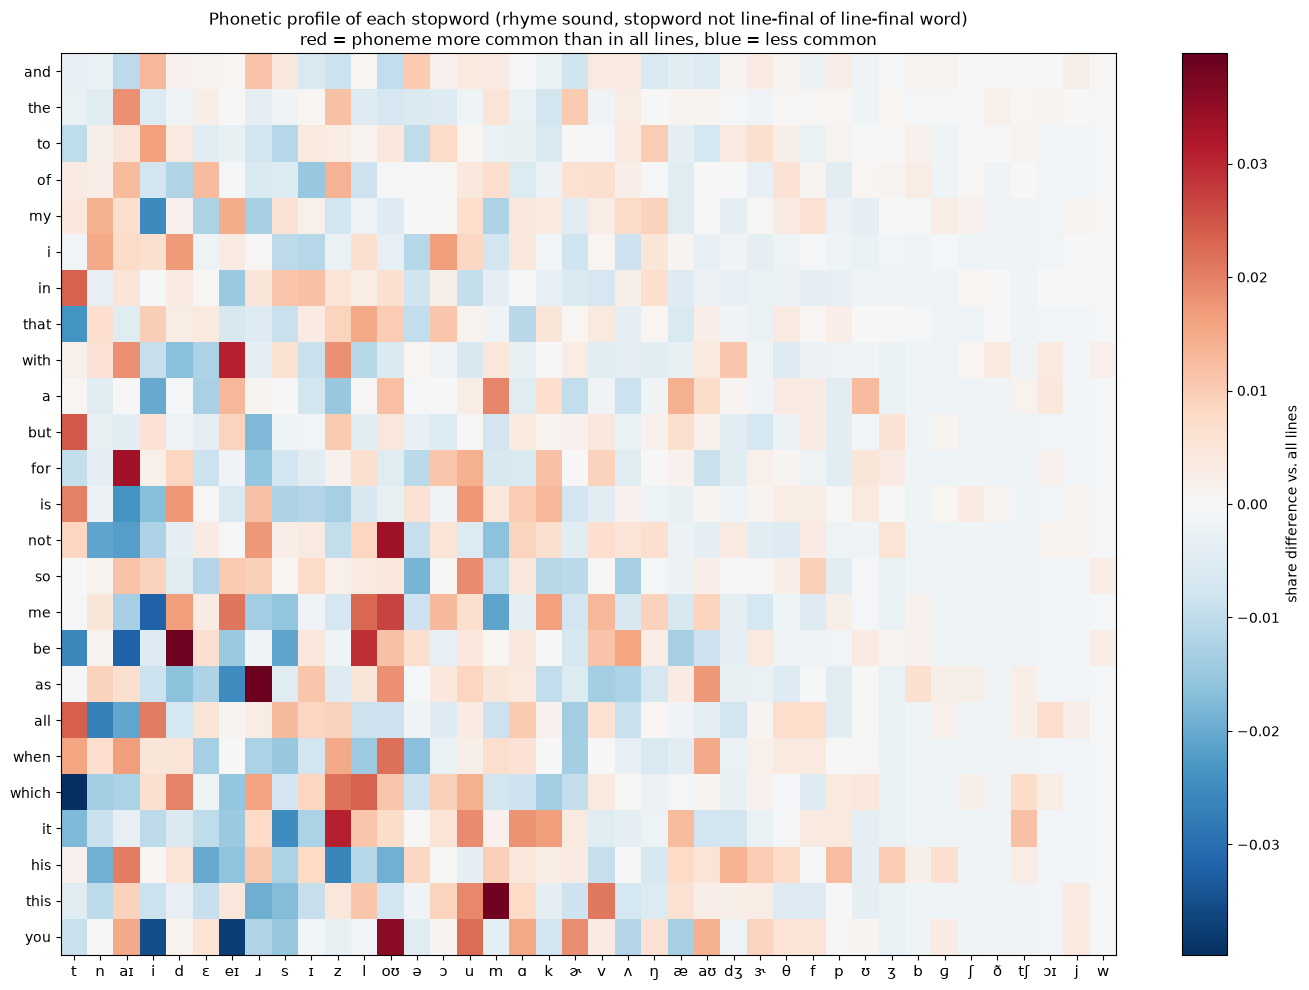

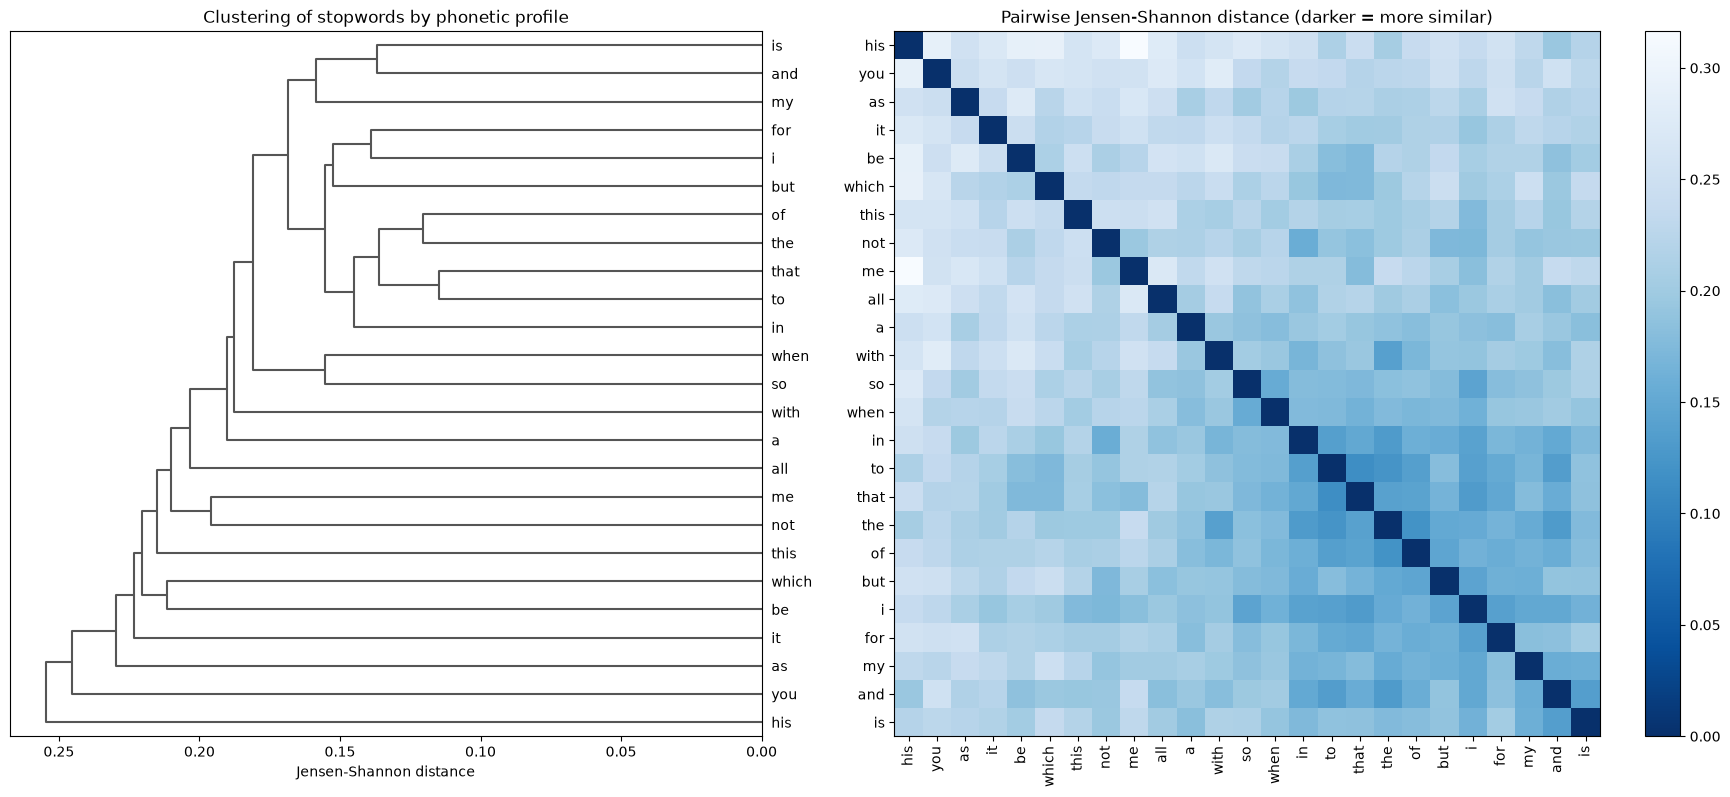

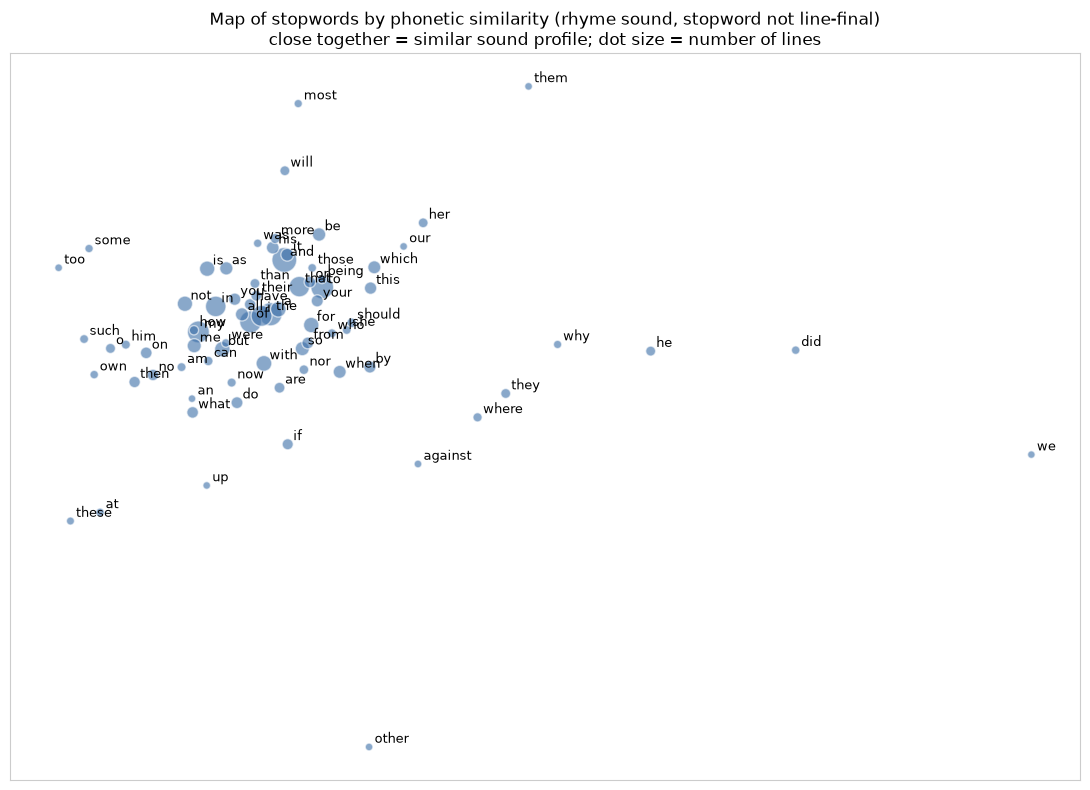

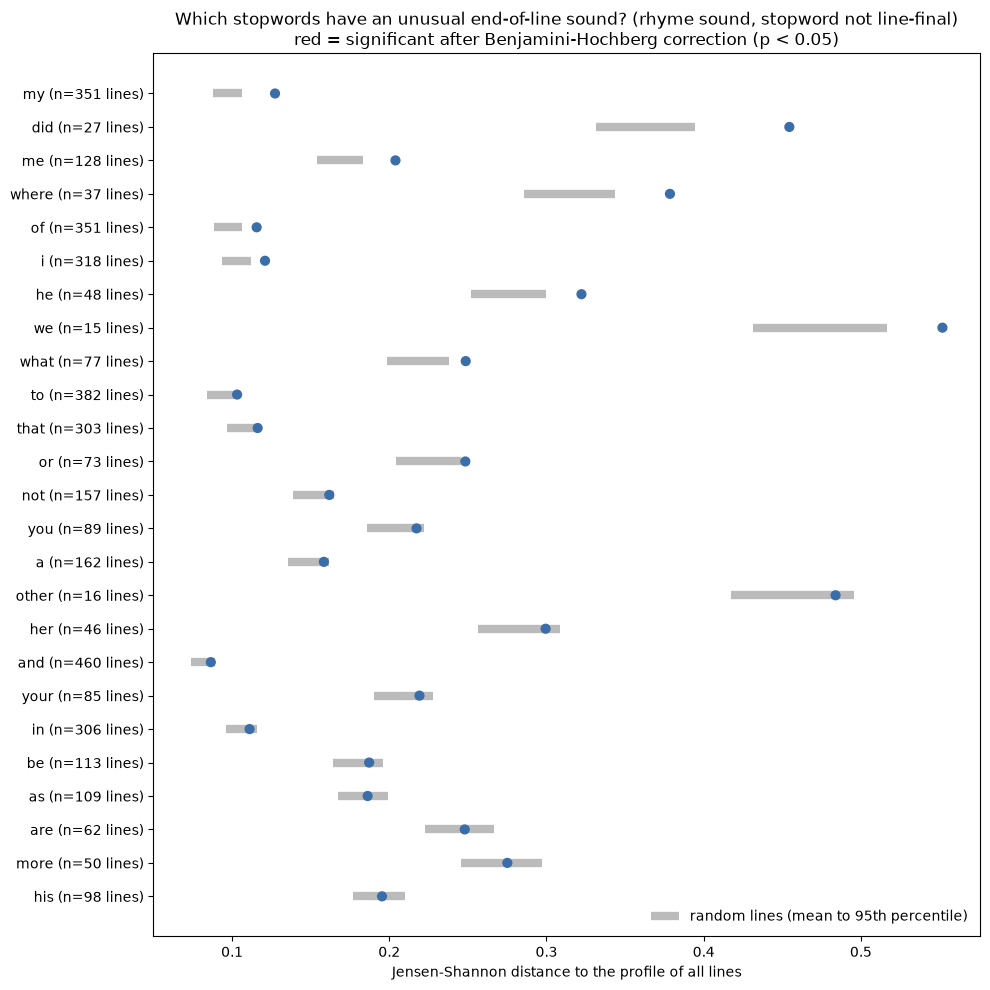


=== rhyme_notfinal profile: 75 stopwords with >= 15 lines ===
  Jensen-Shannon vs Hellinger agreement (Pearson r): 0.998
  most similar pairs:   [('to', 'that', np.float64(0.115)), ('the', 'of', np.float64(0.12)), ('the', 'to', np.float64(0.123)), ('and', 'the', np.float64(0.131)), ('the', 'in', np.float64(0.132))]
  most different pairs: [('at', 'we', np.float64(0.667)), ('too', 'we', np.float64(0.669)), ('our', 'we', np.float64(0.677)), ('up', 'we', np.float64(0.679)), ('these', 'we', np.float64(0.682))]
  significantly distinctive stopwords: 0 of 75

All results written to ./output/task8/


In [2]:
POEMS = {
    "The Lamb": "./poems/thelamb.txt",
    "The Tiger": "./poems/thetiger.txt",
    "Sonnets": "./poems/sonnets.txt",
}
OUT = "./output/task8"
MIN_LINES = 15          # minimum number of lines a stopword must appear in
N_PERMUTATIONS = 2000
TOP_FOR_PLOTS = 25
SEED = 42

# ARPAbet (CMUdict) to IPA, unstressed AH/ER mapped to ə/ɚ
ARPA_TO_IPA = {
    "AA": "ɑ", "AE": "æ", "AH0": "ə", "AH": "ʌ", "AO": "ɔ", "AW": "aʊ",
    "AY": "aɪ", "EH": "ɛ", "ER0": "ɚ", "ER": "ɝ", "EY": "eɪ", "IH": "ɪ",
    "IY": "i", "OW": "oʊ", "OY": "ɔɪ", "UH": "ʊ", "UW": "u",
    "B": "b", "CH": "tʃ", "D": "d", "DH": "ð", "F": "f", "G": "ɡ",
    "HH": "h", "JH": "dʒ", "K": "k", "L": "l", "M": "m", "N": "n",
    "NG": "ŋ", "P": "p", "R": "ɹ", "S": "s", "SH": "ʃ", "T": "t",
    "TH": "θ", "V": "v", "W": "w", "Y": "j", "Z": "z", "ZH": "ʒ",
}
VOWELS = {"AA", "AE", "AH", "AO", "AW", "AY", "EH", "ER", "EY", "IH", "IY",
          "OW", "OY", "UH", "UW"}
IPA_SYMBOLS = list(dict.fromkeys(ARPA_TO_IPA.values()))

WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)*")
CMU = cmudict.dict()
STOPWORDS = set(stopwords.words("english"))


# lower-case, straight apostrophes, remove accents (callèd -> called)
def normalise(text):
    text = text.replace("’", "'").replace("‘", "'").lower()
    text = unicodedata.normalize("NFKD", text)
    return "".join(c for c in text if not unicodedata.combining(c))


# poem lines, skipping empty lines, titles and sonnet numbers
def read_lines(path):
    lines = []
    with open(path, encoding="utf-8") as f:
        for raw in f:
            line = raw.strip()
            if not line or not re.search(r"[a-z]", line):
                continue
            lines.append(line)
    return lines


def arpa_to_ipa(phone):
    base = phone.rstrip("012")
    if base in ("AH", "ER") and phone.endswith("0"):
        return ARPA_TO_IPA[base + "0"]
    return ARPA_TO_IPA[base]


# CMUdict lookup with fallbacks for old spellings (o'er, feed'st, beauty's)
def pronounce(word):
    candidates = [word, word.replace("'", "")]
    if word.endswith("'s"):
        candidates.append(word[:-2])
    if word.endswith("'st") or word.endswith("'d"):
        candidates.append(word.split("'")[0] + ("ed" if word.endswith("'d") else ""))
        candidates.append(word.split("'")[0])
    if word.endswith("st") and len(word) > 4:
        candidates.append(word[:-2])
    for c in candidates:
        if c in CMU:
            return CMU[c][0]
    return None


# phones from the last stressed vowel to the end of the word
def rhyme_part(phones):
    for i in range(len(phones) - 1, -1, -1):
        if phones[i][-1] in "12":
            return phones[i:]
    for i in range(len(phones) - 1, -1, -1):
        if phones[i].rstrip("012") in VOWELS:
            return phones[i:]
    return phones


def to_vector(ipa_list):
    counts = Counter(ipa_list)
    return np.array([counts[s] for s in IPA_SYMBOLS], dtype=float)


def hellinger(p, q):
    return np.sqrt(0.5 * np.sum((np.sqrt(p) - np.sqrt(q)) ** 2))


# Benjamini-Hochberg adjusted p-values
def bh_correct(pvals):
    p = np.asarray(pvals)
    order = np.argsort(p)
    ranked = p[order] * len(p) / (np.arange(len(p)) + 1)
    adjusted = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(adjusted)
    out[order] = np.minimum(adjusted, 1.0)
    return out


# classical MDS: 2-D coordinates from a distance matrix
def classical_mds(d):
    n = len(d)
    j = np.eye(n) - np.ones((n, n)) / n
    b = -0.5 * j @ (d ** 2) @ j
    vals, vecs = np.linalg.eigh(b)
    top = np.argsort(vals)[::-1][:2]
    return vecs[:, top] * np.sqrt(np.maximum(vals[top], 0))


def write_csv(path, header, rows):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(header)
        w.writerows(rows)


# one row per line: last word, its IPA (whole word and rhyme) and stopwords in the line
def build_line_table():
    rows = []
    for poem, path in POEMS.items():
        for n, line in enumerate(read_lines(path), start=1):
            tokens = WORD_RE.findall(normalise(line))
            if not tokens:
                continue
            last = tokens[-1]
            phones = pronounce(last)
            stops_here = sorted({t for t in tokens if t in STOPWORDS})
            if phones is None:
                ipa_word, ipa_rhyme = [], []
            else:
                ipa_word = [arpa_to_ipa(p) for p in phones]
                ipa_rhyme = [arpa_to_ipa(p) for p in rhyme_part(phones)]
            rows.append({
                "poem": poem, "line_no": n, "text": line, "last_word": last,
                "found": phones is not None,
                "ipa_word": ipa_word, "ipa_rhyme": ipa_rhyme,
                "stopwords": stops_here,
            })
    return rows


# phoneme vector per line, line indices per stopword, and the all-lines baseline
# exclude_final drops lines where the stopword itself is the last word
def profiles(rows, key, exclude_final=False):
    usable = [r for r in rows if r["found"]]
    line_vecs = np.array([to_vector(r[key]) for r in usable])
    lines_with = {}
    for i, r in enumerate(usable):
        for s in r["stopwords"]:
            if exclude_final and r["last_word"] == s:
                continue
            lines_with.setdefault(s, []).append(i)
    baseline = line_vecs.sum(axis=0)
    return usable, line_vecs, lines_with, baseline


def analyse(rows, key, label, exclude_final=False):
    usable, line_vecs, lines_with, baseline = profiles(rows, key, exclude_final)
    base_p = baseline / baseline.sum()
    kept = sorted([s for s, idx in lines_with.items() if len(idx) >= MIN_LINES],
                  key=lambda s: -len(lines_with[s]))

    # histogram (counts and probabilities) per stopword
    counts = {s: line_vecs[lines_with[s]].sum(axis=0) for s in kept}
    probs = {s: counts[s] / counts[s].sum() for s in kept}

    write_csv(f"{OUT}/profiles_{label}_counts.csv",
              ["stopword", "n_lines"] + IPA_SYMBOLS,
              [[s, len(lines_with[s])] + counts[s].astype(int).tolist() for s in kept]
              + [["ALL_LINES", len(usable)] + baseline.astype(int).tolist()])
    write_csv(f"{OUT}/profiles_{label}_probabilities.csv",
              ["stopword", "n_lines"] + IPA_SYMBOLS,
              [[s, len(lines_with[s])] + np.round(probs[s], 5).tolist() for s in kept]
              + [["ALL_LINES", len(usable)] + np.round(base_p, 5).tolist()])

    # pairwise distances between stopword histograms
    k = len(kept)
    js = np.zeros((k, k))
    he = np.zeros((k, k))
    for i in range(k):
        for j in range(i + 1, k):
            js[i, j] = js[j, i] = jensenshannon(probs[kept[i]], probs[kept[j]], base=2)
            he[i, j] = he[j, i] = hellinger(probs[kept[i]], probs[kept[j]])
    write_csv(f"{OUT}/distances_{label}_jensenshannon.csv", [""] + kept,
              [[kept[i]] + np.round(js[i], 4).tolist() for i in range(k)])
    write_csv(f"{OUT}/distances_{label}_hellinger.csv", [""] + kept,
              [[kept[i]] + np.round(he[i], 4).tolist() for i in range(k)])
    iu = np.triu_indices(k, 1)
    metric_agreement = np.corrcoef(js[iu], he[iu])[0, 1]

    # permutation test: stopword profile vs. random sets of lines of the same size
    rng = np.random.default_rng(SEED)
    results = []
    for s in kept:
        n = len(lines_with[s])
        observed = jensenshannon(probs[s], base_p, base=2)
        null = np.empty(N_PERMUTATIONS)
        for b in range(N_PERMUTATIONS):
            sample = line_vecs[rng.choice(len(usable), n, replace=False)].sum(axis=0)
            null[b] = jensenshannon(sample / sample.sum(), base_p, base=2)
        p = (np.sum(null >= observed) + 1) / (N_PERMUTATIONS + 1)
        top = [IPA_SYMBOLS[i] for i in np.argsort(-(probs[s] - base_p))[:3]]
        results.append([s, n, observed, np.mean(null), np.percentile(null, 95), p, top])
    adj = bh_correct([r[5] for r in results])
    for r, a in zip(results, adj):
        r.append(a)
    write_csv(f"{OUT}/distinctiveness_{label}.csv",
              ["stopword", "n_lines", "js_to_all_lines", "null_mean", "null_95pct",
               "p_value", "most_overrepresented_ipa", "p_adjusted_BH"],
              [[r[0], r[1], round(r[2], 4), round(r[3], 4), round(r[4], 4),
                round(r[5], 4), " ".join(r[6]), round(r[7], 4)] for r in results])

    plot_all(kept, probs, base_p, js, results, label)
    return kept, js, results, metric_agreement, len(usable)


def plot_all(kept, probs, base_p, js, results, label):
    title_part = {"rhyme": "rhyme sound", "word": "whole end-word",
                  "rhyme_notfinal": "rhyme sound, stopword not line-final"}[label]
    show = kept[:TOP_FOR_PLOTS]
    idx = [kept.index(s) for s in show]
    used = [i for i in np.argsort(-base_p) if base_p[i] > 0]

    # heatmap: phoneme share per stopword minus share in all lines
    diff = np.array([probs[s][used] - base_p[used] for s in show])
    lim = np.abs(diff).max()
    fig, ax = plt.subplots(figsize=(14, 0.32 * len(show) + 2))
    im = ax.imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(used)), [IPA_SYMBOLS[i] for i in used], fontsize=11)
    ax.set_yticks(range(len(show)), show)
    ax.set_title(f"Phonetic profile of each stopword ({title_part} of line-final word)\n"
                 "red = phoneme more common than in all lines, blue = less common")
    fig.colorbar(im, ax=ax, label="share difference vs. all lines")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # dendrogram and distance matrix ordered by clustering
    sub = js[np.ix_(idx, idx)]
    Z = linkage(squareform(sub, checks=False), method="average")
    order = leaves_list(Z)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 8),
                                 gridspec_kw={"width_ratios": [1, 1.2]})
    dendrogram(Z, labels=show, orientation="left", ax=a1, color_threshold=0,
               above_threshold_color="#555555")
    a1.set_title("Clustering of stopwords by phonetic profile")
    a1.set_xlabel("Jensen-Shannon distance")
    im = a2.imshow(sub[np.ix_(order, order)], cmap="Blues_r")
    names = [show[i] for i in order]
    a2.set_xticks(range(len(names)), names, rotation=90)
    a2.set_yticks(range(len(names)), names)
    a2.set_title("Pairwise Jensen-Shannon distance (darker = more similar)")
    fig.colorbar(im, ax=a2)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # 2-D MDS map of the distance matrix
    xy = classical_mds(js)
    n_lines = np.array([r[1] for r in results])
    fig, ax = plt.subplots(figsize=(11, 8))
    ax.scatter(xy[:, 0], xy[:, 1], s=20 + 300 * n_lines / n_lines.max(),
               color="#3b6ea8", alpha=0.6, edgecolor="white", linewidth=1)
    for (x, y), s in zip(xy, kept):
        ax.annotate(s, (x, y), fontsize=9, xytext=(4, 3), textcoords="offset points")
    ax.set_title(f"Map of stopwords by phonetic similarity ({title_part})\n"
                 "close together = similar sound profile; dot size = number of lines")
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color("#cccccc")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

    # distance to all lines vs. random-line range, sorted by excess over random
    res = sorted(results, key=lambda r: -(r[2] - r[3]) / (r[4] - r[3] + 1e-9))[:TOP_FOR_PLOTS]
    fig, ax = plt.subplots(figsize=(10, 0.32 * len(res) + 2))
    y = np.arange(len(res))
    ax.hlines(y, [r[3] for r in res], [r[4] for r in res], color="#bbbbbb", lw=6,
              label="random lines (mean to 95th percentile)")
    sig = [r[7] < 0.05 for r in res]
    ax.scatter([r[2] for r in res], y, color=["#c0392b" if s else "#3b6ea8" for s in sig],
               zorder=3, s=40)
    ax.set_yticks(y, [f"{r[0]} (n={r[1]} lines)" for r in res])
    ax.invert_yaxis()
    ax.set_xlabel("Jensen-Shannon distance to the profile of all lines")
    ax.set_title(f"Which stopwords have an unusual end-of-line sound? ({title_part})\n"
                 "red = significant after Benjamini-Hochberg correction (p < 0.05)")
    ax.legend(loc="lower right", frameon=False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def main():
    os.makedirs(OUT, exist_ok=True)
    rows = build_line_table()

    write_csv(f"{OUT}/lines.csv",
              ["poem", "line_no", "text", "last_word", "in_cmudict",
               "ipa_word", "ipa_rhyme", "stopwords_in_line"],
              [[r["poem"], r["line_no"], r["text"], r["last_word"], r["found"],
                " ".join(r["ipa_word"]), " ".join(r["ipa_rhyme"]),
                " ".join(r["stopwords"])] for r in rows])

    print("Lines per poem / end-words found in CMUdict:")
    for poem in POEMS:
        pr = [r for r in rows if r["poem"] == poem]
        found = sum(r["found"] for r in pr)
        print(f"  {poem:10s} {len(pr):5d} lines, {found:5d} found ({100*found/len(pr):.1f}%)")
    missing = Counter(r["last_word"] for r in rows if not r["found"])
    print("  most common end-words not in CMUdict:", missing.most_common(10))

    # how often each stopword is itself the line-final word
    final_counts = Counter(r["last_word"] for r in rows if r["last_word"] in STOPWORDS)
    line_counts = Counter(s for r in rows for s in r["stopwords"])
    write_csv(f"{OUT}/stopwords_line_final.csv",
              ["stopword", "lines_containing", "times_line_final", "share_line_final"],
              [[s, line_counts[s], final_counts[s], round(final_counts[s] / line_counts[s], 3)]
               for s in sorted(line_counts, key=lambda x: -line_counts[x])])
    print("\nStopwords most often used as the line-final word:",
          [(s, c, f"{100*c/line_counts[s]:.0f}% of its lines") for s, c in final_counts.most_common(8)])

    for key, label, excl in (("ipa_rhyme", "rhyme", False),
                             ("ipa_word", "word", False),
                             ("ipa_rhyme", "rhyme_notfinal", True)):
        kept, js, results, agree, n = analyse(rows, key, label, excl)
        iu = np.triu_indices(len(kept), 1)
        pairs = sorted(zip(js[iu], [kept[i] for i in iu[0]], [kept[j] for j in iu[1]]))
        print(f"\n=== {label} profile: {len(kept)} stopwords with >= {MIN_LINES} lines ===")
        print(f"  Jensen-Shannon vs Hellinger agreement (Pearson r): {agree:.3f}")
        print("  most similar pairs:  ", [(a, b, round(d, 3)) for d, a, b in pairs[:5]])
        print("  most different pairs:", [(a, b, round(d, 3)) for d, a, b in pairs[-5:]])
        sig = sorted([r for r in results if r[7] < 0.05], key=lambda r: r[7])
        print(f"  significantly distinctive stopwords: {len(sig)} of {len(results)}")
        for r in sig[:10]:
            print(f"    {r[0]:8s} n={r[1]:4d} JS={r[2]:.3f} (random ~{r[3]:.3f}) "
                  f"p_adj={r[7]:.4f} more: {' '.join(r[6])}")
    print(f"\nAll results written to {OUT}/")


if __name__ == "__main__":
    main()
